<a href="https://colab.research.google.com/github/Crisstudy/Aplicacao-de-Ciencia-de-Dados-para-Negocios/blob/main/atividade_pratica_aula_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import numpy as np

In [ ]:

#Criando dados ficticios ao longo do tempo
np.random.seed(42)
meses = pd.date_range(start='2023-01-01', periods=24, freq='M')
vendas = np.random.randint(80000, 120000, size=24) + np.arange(24) * 2000

df = pd.DataFrame({'Mes' : meses, 'Vendas' : vendas})

# Configurando o índice como a coluna de datas
df.set_index('Mes', inplace=True)
df

/tmp/ipykernel_1051/1562285586.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  meses = pd.date_range(start='2023-01-01', periods=24, freq='M')


,Vendas
Mes,
2023-01-31,95795
2023-02-28,82860
2023-03-31,122158
2023-04-30,97284
2023-05-31,94265
2023-06-30,106850
2023-07-31,129194
2023-08-31,115962
2023-09-30,112023


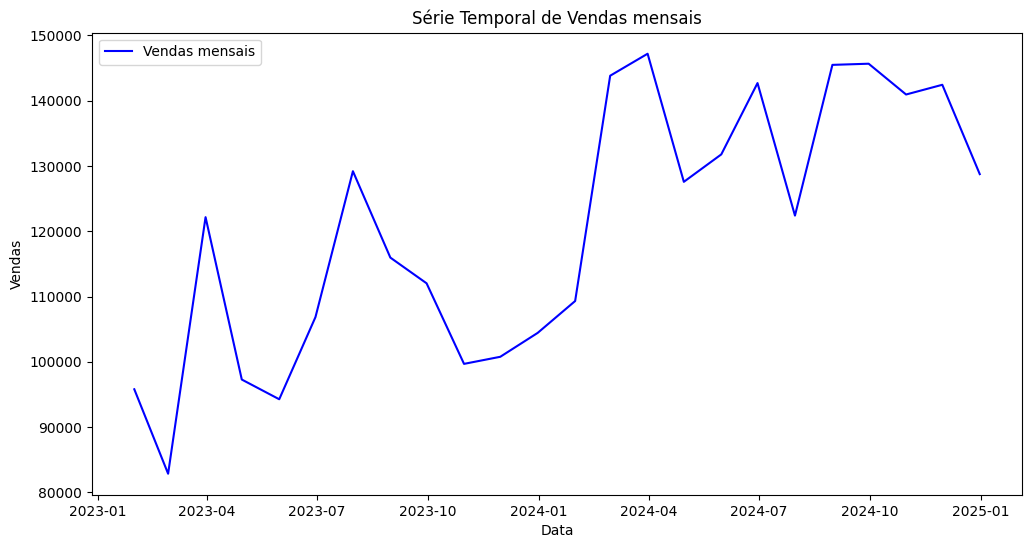

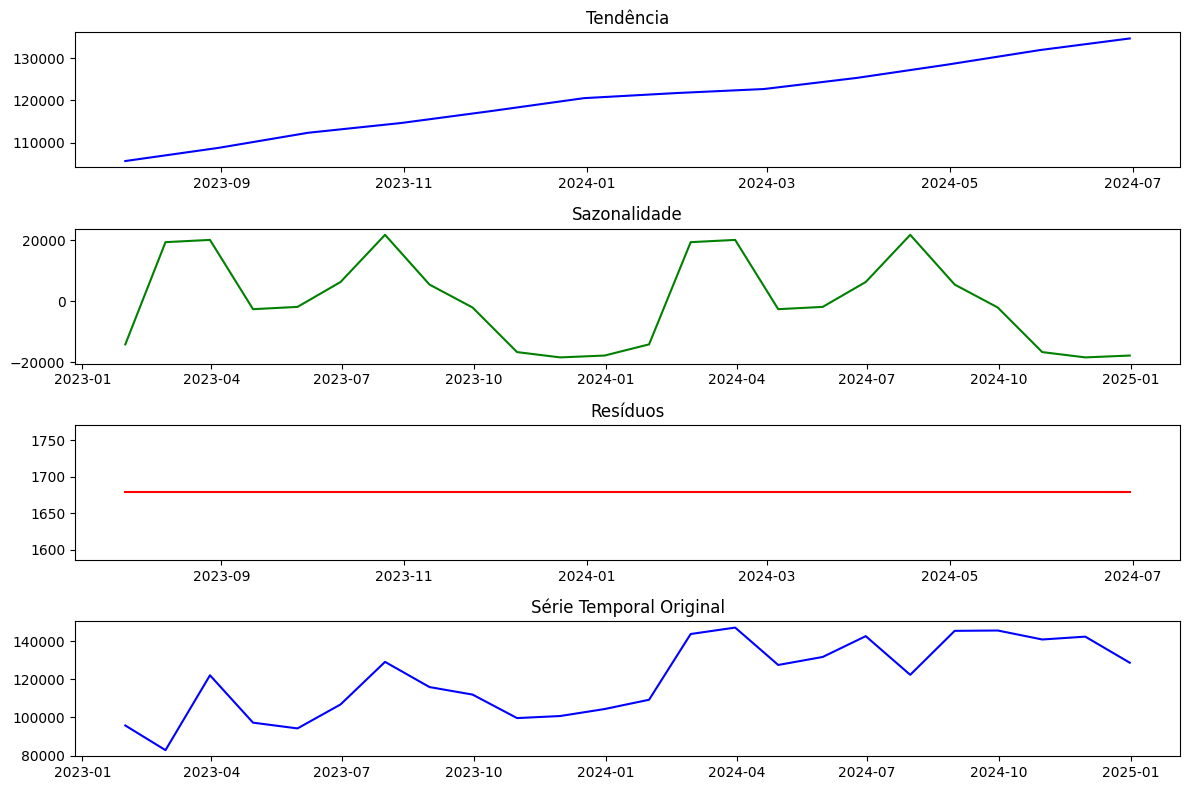

In [ ]:
# Visualizando a serie temporal
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Vendas'], label='Vendas mensais', color='blue')
plt.title('Série Temporal de Vendas mensais')
plt.xlabel('Data')
plt.ylabel('Vendas')
plt.legend()
plt.show()

# Decompondo a serie temporal em tendência, sazonalidade e resídios
decomposicao = sm.tsa.seasonal_decompose(df['Vendas'], model='additive', period=12)

# Visualizando as componentes da decomposição
plt.figure(figsize=(12, 8))

plt.subplot(4, 1, 1)
plt.plot(decomposicao.trend, label='Tendência', color='blue')
plt.title('Tendência')

plt.subplot(4, 1, 2)
plt.plot(decomposicao.seasonal, label='Sazonalidade', color='green')
plt.title('Sazonalidade')

plt.subplot(4, 1, 3)
plt.plot(decomposicao.resid, label='Resíduos', color='red')
plt.title('Resíduos')

plt.subplot(4, 1, 4)
plt.plot(df['Vendas'], label='Vendas mensais', color='blue')
plt.title('Série Temporal Original')

plt.tight_layout()
plt.show()
